In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in dte_coimaging_analysis.py next to this notebook
# (run it as a script to regenerate everything: python dte_coimaging_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import dte_coimaging_analysis as dte

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
figdir = dte.DEFAULT_FIGDIR     # data: see dte.DATA_PATH
figdir.mkdir(parents=True, exist_ok=True)
data, channel_lookup = dte.load_data()
print(f'{len(data)} flies')

10 flies


/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/dte_coimaging_analysis.py:57: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  data = pickle.load(f)


## Heatmaps of every trial

In [3]:
n_trials = dte.plot_trial_heatmaps(figdir, data, channel_lookup)
print(f'{n_trials} trials')

50 trials


## Offset difference between EPG and EL

| offset diff | vs chance: {'n': 10, 'W': 0.0, 'p': 0.001953125, 'dof': 9}


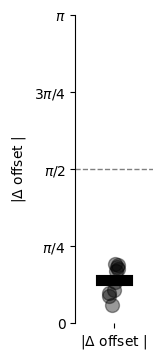

In [4]:
fig, offset_unique, test = dte.plot_abs_offset_diff(figdir, data, channel_lookup)
print('| offset diff | vs chance:', test)

## PV magnitude and PVA difference vs rotation speed

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/dte_coimaging_analysis.py:168: RuntimeWarning: Mean of empty slice
  return {col: stats_df.groupby(['fly_id', 'cl'])[col].apply(lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/dte_coimaging_analysis.py:168: RuntimeWarning: Mean of empty slice
  return {col: stats_df.groupby(['fly_id', 'cl'])[col].apply(lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/dte_coimaging_analysis.py:168: RuntimeWarning: Mean of empty slice
  return {col: stats_df.groupby(['fly_id', 'cl'])[col].apply(lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


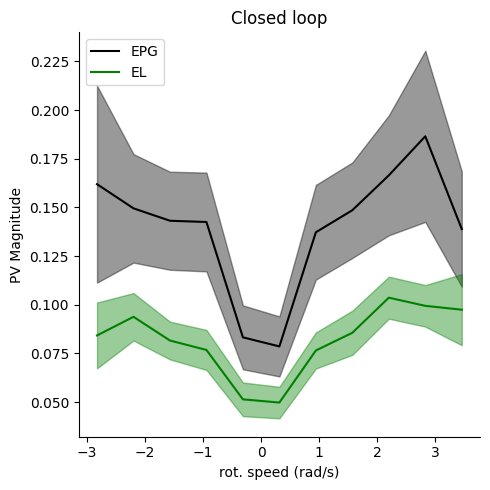

In [5]:
grouped = dte.compute_binned_stats(data, channel_lookup)
fig = dte.plot_rho_vs_speed(figdir, grouped)

{'closed loop': {'r': 0.8208248857131349, 'p': 4.221976409203719e-24}}

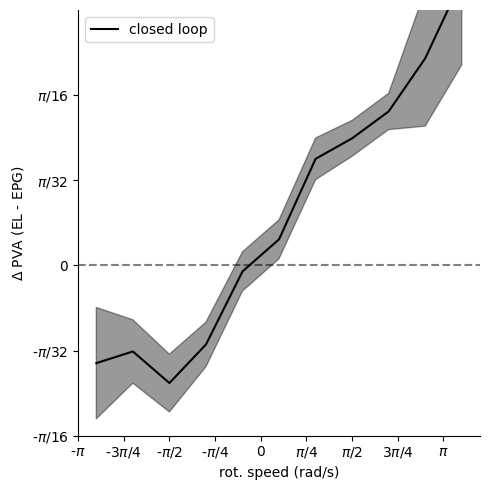

In [6]:
fig, spearman = dte.plot_pva_diff_vs_speed(figdir, grouped)
spearman

## Bump width: EL vs EPG

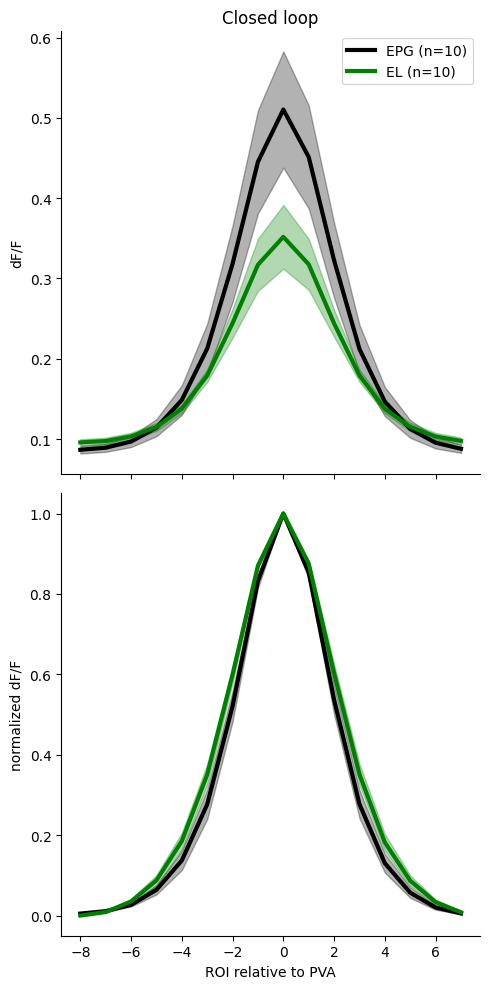

In [7]:
grouped_bump = dte.compute_bump_stats(data, channel_lookup)
fig = dte.plot_bump_profiles(figdir, grouped_bump)

,condition,comparison,n,W,p,median_diff,p_holm
0,closed loop,EL vs EPG,10,15.0,0.232422,0.179781,0.232422


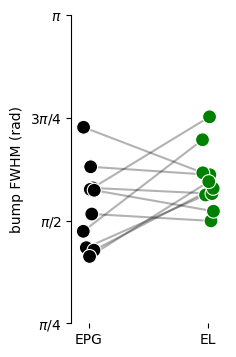

In [8]:
fig, width_tests = dte.plot_bump_width(figdir, grouped_bump)
width_tests

## Bump profiles during fast turns

{'clockwise': {'EPG': -7.807287324542532e-17, 'EL': -0.12526456366895447},
 'counter-clockwise': {'EPG': -1.2304328088927513e-16,
  'EL': 0.17134812117176826}}

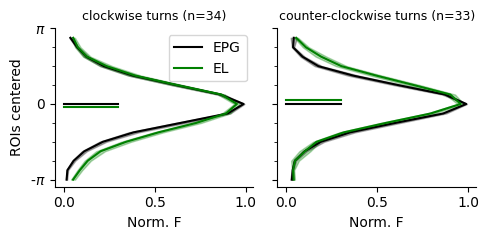

In [9]:
fig, turn_pva = dte.plot_turn_profiles(figdir, data, channel_lookup)
turn_pva